<a href="https://colab.research.google.com/github/SrishanthGorla/SERAI/blob/main/Privacy_Risk_Baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

np.random.seed(42)

n = 100

names = [f"Person_{i:03d}" for i in range(1, n + 1)]

dataset = pd.DataFrame({
    "record_id": range(1, n + 1),
    "name": names,
    "email": [f"person{i:03d}@example.com" for i in range(1, n + 1)],
    "age": np.random.randint(18, 66, n),
    "city": np.random.choice(
        ["Warangal", "Hyderabad", "Chennai", "Bengaluru"], n
    ),
    "occupation": np.random.choice(
        ["Student", "Employee", "Business", "Other"], n
    ),
    "salary": np.random.randint(15000, 100001, n),
    "medical_condition": np.random.choice(
        ["Yes", "No"], n, p=[0.35, 0.65]
    )
})

# Add a small number of missing values for analysis
dataset.loc[[5, 20], "salary"] = np.nan

print("Dataset created successfully!")
print("Dataset shape:", dataset.shape)
display(dataset.head(10))


Dataset created successfully!
Dataset shape: (100, 8)


,record_id,name,email,age,city,occupation,salary,medical_condition
0,1,Person_001,person001@example.com,56,Bengaluru,Other,87082.0,No
1,2,Person_002,person002@example.com,46,Bengaluru,Student,49754.0,No
2,3,Person_003,person003@example.com,32,Bengaluru,Business,26411.0,No
3,4,Person_004,person004@example.com,60,Chennai,Employee,17911.0,No
4,5,Person_005,person005@example.com,25,Chennai,Student,82270.0,No
5,6,Person_006,person006@example.com,38,Chennai,Student,NaN,Yes
6,7,Person_007,person007@example.com,56,Warangal,Student,23680.0,No
7,8,Person_008,person008@example.com,36,Bengaluru,Business,99896.0,No
8,9,Person_009,person009@example.com,40,Chennai,Employee,98879.0,Yes
9,10,Person_010,person010@example.com,28,Chennai,Student,86295.0,Yes


In [5]:

print("Number of records:", len(dataset))
print("Number of columns:", len(dataset.columns))

print("\nColumn names:")
print(dataset.columns.tolist())

print("\nData types:")
print(dataset.dtypes)

print("\nMissing values:")
print(dataset.isnull().sum())

print("\nMedical condition distribution:")
print(dataset["medical_condition"].value_counts())

print("\nStatistical summary:")
display(dataset.describe(include="all"))


Number of records: 100
Number of columns: 8

Column names:
['record_id', 'name', 'email', 'age', 'city', 'occupation', 'salary', 'medical_condition']

Data types:
record_id              int64
name                  object
email                 object
age                    int64
city                  object
occupation            object
salary               float64
medical_condition     object
dtype: object

Missing values:
record_id            0
name                 0
email                0
age                  0
city                 0
occupation           0
salary               2
medical_condition    0
dtype: int64

Medical condition distribution:
medical_condition
No     69
Yes    31
Name: count, dtype: int64

Statistical summary:


,record_id,name,email,age,city,occupation,salary,medical_condition
count,100.000000,100,100,100.000000,100,100,98.000000,100
unique,NaN,100,100,NaN,4,4,NaN,2
top,NaN,Person_001,person001@example.com,NaN,Chennai,Other,NaN,No
freq,NaN,1,1,NaN,34,28,NaN,69
mean,50.500000,NaN,NaN,40.920000,NaN,NaN,55062.969388,NaN
std,29.011492,NaN,NaN,14.054497,NaN,NaN,24774.636516,NaN
min,1.000000,NaN,NaN,18.000000,NaN,NaN,16802.000000,NaN
25%,25.750000,NaN,NaN,30.500000,NaN,NaN,33876.250000,NaN
50%,50.500000,NaN,NaN,41.000000,NaN,NaN,56730.000000,NaN
75%,75.250000,NaN,NaN,53.250000,NaN,NaN,75294.750000,NaN


In [6]:

direct_identifiers = ["record_id", "name", "email"]

quasi_identifiers = ["age", "city", "occupation"]

sensitive_fields = ["salary", "medical_condition"]

field_classification = pd.DataFrame({
    "Field": direct_identifiers + quasi_identifiers + sensitive_fields,
    "Category": (
        ["Direct identifier"] * len(direct_identifiers)
        + ["Quasi-identifier"] * len(quasi_identifiers)
        + ["Sensitive field"] * len(sensitive_fields)
    ),
    "Privacy risk": (
        ["High"] * len(direct_identifiers)
        + ["Medium"] * len(quasi_identifiers)
        + ["High"] * len(sensitive_fields)
    )
})

display(field_classification)


,Field,Category,Privacy risk
0,record_id,Direct identifier,High
1,name,Direct identifier,High
2,email,Direct identifier,High
3,age,Quasi-identifier,Medium
4,city,Quasi-identifier,Medium
5,occupation,Quasi-identifier,Medium
6,salary,Sensitive field,High
7,medical_condition,Sensitive field,High


In [7]:

quasi_columns = ["age", "city", "occupation"]

group_sizes = dataset.groupby(
    quasi_columns, dropna=False
)["record_id"].transform("count")

dataset["quasi_identifier_group_size"] = group_sizes
dataset["unique_combination"] = group_sizes == 1

unique_count = int(dataset["unique_combination"].sum())
unique_percentage = unique_count / len(dataset) * 100

print("Records with unique quasi-identifier combinations:",
      unique_count)
print(f"Percentage of records with unique combinations: "
      f"{unique_percentage:.2f}%")

print("\nExample records with unique combinations:")
display(
    dataset.loc[
        dataset["unique_combination"],
        quasi_columns + ["salary", "medical_condition"]
    ].head(10)
)


Records with unique quasi-identifier combinations: 90
Percentage of records with unique combinations: 90.00%

Example records with unique combinations:


,age,city,occupation,salary,medical_condition
0,56,Bengaluru,Other,87082.0,No
1,46,Bengaluru,Student,49754.0,No
3,60,Chennai,Employee,17911.0,No
4,25,Chennai,Student,82270.0,No
5,38,Chennai,Student,NaN,Yes
6,56,Warangal,Student,23680.0,No
7,36,Bengaluru,Business,99896.0,No
8,40,Chennai,Employee,98879.0,Yes
9,28,Chennai,Student,86295.0,Yes
10,28,Warangal,Other,26111.0,No


In [8]:

from sklearn.impute import SimpleImputer

features = ["age", "city", "occupation", "salary"]
target = "medical_condition"

X = dataset[features]
y = dataset[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_features = ["age", "salary"]
categorical_features = ["city", "occupation"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Model trained successfully!
Training records: 80
Testing records: 20


In [9]:

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(
    y_test, predictions, pos_label="Yes", zero_division=0
)
recall = recall_score(
    y_test, predictions, pos_label="Yes", zero_division=0
)
f1 = f1_score(
    y_test, predictions, pos_label="Yes", zero_division=0
)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [accuracy, precision, recall, f1]
})

display(results.round(3))

print("\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))


,Metric,Score
0,Accuracy,0.700
1,Precision,0.500
2,Recall,0.167
3,F1-score,0.250



Classification report:
              precision    recall  f1-score   support

          No       0.72      0.93      0.81        14
         Yes       0.50      0.17      0.25         6

    accuracy                           0.70        20
   macro avg       0.61      0.55      0.53        20
weighted avg       0.66      0.70      0.64        20



In [10]:

reduced_dataset = dataset.drop(
    columns=["name", "email", "record_id",
             "quasi_identifier_group_size", "unique_combination"]
)

print("Original dataset columns:", len(dataset.columns))
print("Reduced dataset columns:", len(reduced_dataset.columns))

print("\nReduced dataset preview:")
display(reduced_dataset.head())

print("\nDirect identifiers remaining:",
      [c for c in ["name", "email", "record_id"]
       if c in reduced_dataset.columns])


Original dataset columns: 10
Reduced dataset columns: 5

Reduced dataset preview:


,age,city,occupation,salary,medical_condition
0,56,Bengaluru,Other,87082.0,No
1,46,Bengaluru,Student,49754.0,No
2,32,Bengaluru,Business,26411.0,No
3,60,Chennai,Employee,17911.0,No
4,25,Chennai,Student,82270.0,No



Direct identifiers remaining: []


In [11]:

risk_table = pd.DataFrame([
    {
        "Risk area": "Direct identifiers",
        "Example": "Name and email",
        "Likelihood": "High",
        "Impact": "High",
        "Mitigation": "Remove or replace with controlled pseudonyms"
    },
    {
        "Risk area": "Re-identification",
        "Example": "Age + city + occupation",
        "Likelihood": "Medium",
        "Impact": "High",
        "Mitigation": "Generalize or suppress identifying combinations"
    },
    {
        "Risk area": "Sensitive data exposure",
        "Example": "Salary and medical condition",
        "Likelihood": "Medium",
        "Impact": "High",
        "Mitigation": "Restrict access and minimize collected fields"
    },
    {
        "Risk area": "Inference from model",
        "Example": "Predicting medical condition",
        "Likelihood": "Medium",
        "Impact": "High",
        "Mitigation": "Evaluate inference risk and limit model outputs"
    },
    {
        "Risk area": "Logs and outputs",
        "Example": "Printing personal fields in logs",
        "Likelihood": "Medium",
        "Impact": "Medium",
        "Mitigation": "Redact logs and avoid exposing raw records"
    },
    {
        "Risk area": "Excessive retention",
        "Example": "Keeping data longer than needed",
        "Likelihood": "Medium",
        "Impact": "Medium",
        "Mitigation": "Define a retention period and delete securely"
    }
])

display(risk_table)


,Risk area,Example,Likelihood,Impact,Mitigation
0,Direct identifiers,Name and email,High,High,Remove or replace with controlled pseudonyms
1,Re-identification,Age + city + occupation,Medium,High,Generalize or suppress identifying combinations
2,Sensitive data exposure,Salary and medical condition,Medium,High,Restrict access and minimize collected fields
3,Inference from model,Predicting medical condition,Medium,High,Evaluate inference risk and limit model outputs
4,Logs and outputs,Printing personal fields in logs,Medium,Medium,Redact logs and avoid exposing raw records
5,Excessive retention,Keeping data longer than needed,Medium,Medium,Define a retention period and delete securely


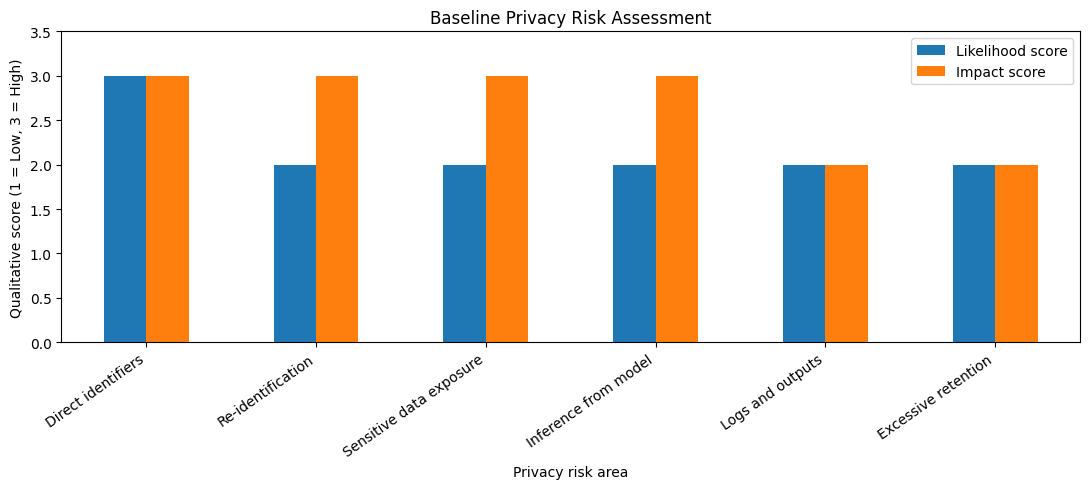

In [12]:

risk_levels = {"Low": 1, "Medium": 2, "High": 3}

plot_data = risk_table.copy()
plot_data["Likelihood score"] = (
    plot_data["Likelihood"].map(risk_levels)
)
plot_data["Impact score"] = plot_data["Impact"].map(risk_levels)

plot_data.plot(
    x="Risk area",
    y=["Likelihood score", "Impact score"],
    kind="bar",
    figsize=(11, 5)
)

plt.title("Baseline Privacy Risk Assessment")
plt.ylabel("Qualitative score (1 = Low, 3 = High)")
plt.xlabel("Privacy risk area")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 3.5)
plt.tight_layout()
plt.show()


In [13]:

dataset.to_csv("synthetic_privacy_dataset.csv", index=False)
field_classification.to_csv(
    "field_classification.csv", index=False
)
risk_table.to_csv("baseline_privacy_risk_table.csv", index=False)
results.to_csv("model_evaluation_results.csv", index=False)

print("All output files saved successfully!")


All output files saved successfully!
